# Validasi Data, Prediksi Efisiensi & Deteksi Anomali Sensor Pembangkit Listrik

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/power-plant-anomaly/blob/main/power_plant_anomaly.ipynb)

Notebook ini menjawab empat pertanyaan tentang data operasi pembangkit listrik tenaga uap (PLTU):
1. Apakah datanya bisa dipercaya (konsisten dengan rumus dan kaidah fisika)?
2. Bisakah efisiensi boiler dan HP turbine diprediksi, dan berapa menit ke depan?
3. Sensor mana yang paling berpengaruh pada prediksi efisiensi?
4. Kapan sensor membaca nilai tidak wajar, dan seberapa andal alarmnya?

Semua teks temuan, judul slide, dan kesimpulan **dihitung otomatis dari data**, jadi tetap benar bila datanya ditambah atau dikurangi.

## 1. Data

Data diunduh dari Google Drive (CSV, satu baris per 10 menit). Kolom dibagi tiga:
- **Target:** efisiensi HP turbine dan efisiensi boiler.
- **Kolom turunan:** angka yang *dihitung* dari sensor lewat rumus, misalnya entalpi dan heat rate. Kolom ini tidak boleh dipakai untuk memprediksi efisiensi karena isinya bocoran dari target (*data leakage*).
- **Sensor:** besaran yang diukur langsung, yaitu suhu, tekanan, aliran, emisi, dan beban.

In [1]:
import os, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from IPython.display import Markdown, display
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

CSV = 'industrial_dataset.csv'
if not os.path.exists(CSV):
    import gdown
    gdown.download(id='1B89CtLiDWSVutzxSLESP7O9XWwqh9mQX', output=CSV, quiet=True)
df = pd.read_csv(CSV, parse_dates=['Timestamp']).sort_values('Timestamp').reset_index(drop=True)

TARGET = ['HP Turbine eff (%)', 'Boiler Eff (%)']
TURUNAN = ['Entalphy inlet MS (kj/kg)', 'Entropi Inlet MS (Kj/Kg (Deg C))', 'Entalphy Cold Reheat (kj/kg)',
           'Entalphy Isentropis Cold Reheat (kj/kg)', 'ΔP aktual (Kj/Kg)', 'ΔHP isentropis (Kj/Kg)',
           'APH Leakage (%)', 'Corrected Flue Gas Out Temperature (°C)', 'APH Effectiveness (%)',
           'Energy Input From Boiler (Kcal/h)', 'NTHR (Kcal/Kwh)', 'NPHR (Kcal/Kwh)']
SENSOR = [c for c in df.columns if c not in ['Timestamp', *TARGET, *TURUNAN]]

fmt = lambda x, d=2: f'{round(x, d) + 0:,.{d}f}'.translate(str.maketrans(',.', '.,'))  # format angka Indonesia
BLN = 'Jan Feb Mar Apr Mei Jun Jul Agu Sep Okt Nov Des'.split()
tgl = lambda t: f'{t.day} {BLN[t.month - 1]} {t.year}'
tulis = lambda teks: display(Markdown(teks))
os.makedirs('images', exist_ok=True)

PERIODE = f"{tgl(df['Timestamp'].iloc[0])} – {tgl(df['Timestamp'].iloc[-1])}"
tulis(f'**Data:** {fmt(len(df), 0)} baris, {PERIODE}, {len(SENSOR)} sensor, {len(TURUNAN)} kolom turunan, {len(TARGET)} target.')

**Data:** 50.091 baris, 1 Jan 2022 – 14 Des 2022, 40 sensor, 12 kolom turunan, 2 target.

## 2. Validasi data: apakah angkanya bisa dipercaya?

Sebelum membuat model, data dicek dengan tiga jenis cek:
- **Rumus:** kolom turunan harus sama dengan hasil rumusnya (toleransi 0,1%). Contohnya, efisiensi HP turbine = penurunan entalpi aktual ÷ penurunan entalpi isentropis × 100.
- **Fisik:** kaidah dasar harus terpenuhi, misalnya Nett Load selalu lebih kecil dari Gross Load.
- **Keterkaitan:** besaran yang saling bergantung harus bergerak bersama. Contohnya, kalau main steam flow naik, beban (MW) juga naik.

Cek rumus dan fisik **Lulus** bila terpenuhi di ≥ 99% baris. Cek keterkaitan **Lulus** bila korelasi Spearman ρ ≥ 0,5.

In [2]:
h_ms, dp, dhs = df['Entalphy inlet MS (kj/kg)'], df['ΔP aktual (Kj/Kg)'], df['ΔHP isentropis (Kj/Kg)']
rumus = {  # cek: (nilai di data, nilai dari rumus)
    'ΔP aktual = h_MS − h_CRH': (dp, h_ms - df['Entalphy Cold Reheat (kj/kg)']),
    'ΔH isentropis = h_MS − h_CRH,s': (dhs, h_ms - df['Entalphy Isentropis Cold Reheat (kj/kg)']),
    'η HP = ΔP ÷ ΔH isentropis × 100': (df['HP Turbine eff (%)'], dp / dhs * 100),
    'NTHR = energi input ÷ Nett Load': (df['NTHR (Kcal/Kwh)'], df['Energy Input From Boiler (Kcal/h)'] / (df['Nett Load (MW)'] * 1e3)),
    'NPHR = NTHR ÷ η boiler': (df['NPHR (Kcal/Kwh)'], df['NTHR (Kcal/Kwh)'] / (df['Boiler Eff (%)'] / 100)),
}
fisik = {
    'Nett Load < Gross Load': df['Nett Load (MW)'] < df['Gross Load (MW)'],
    'Suhu main steam: turbin ≤ boiler': df['Main steam temperature (turbine side) (℃)'] <= df['Main steam temperature (boiler side) (℃)'],
    'Interval 10 menit, tanpa data kosong': df['Timestamp'].diff().fillna(pd.Timedelta('10min')).eq(pd.Timedelta('10min')) & df.notna().all(axis=1),
}
keterkaitan = {
    'Main steam flow ↔ Gross Load': ('Main steam flow (t/h)', 'Gross Load (MW)'),
    'Coal Flow ↔ Gross Load': ('Coal Flow (t/h)', 'Gross Load (MW)'),
    'Gross Load ↔ Nett Load': ('Gross Load (MW)', 'Nett Load (MW)'),
}
rho = df.drop(columns='Timestamp').corr(method='spearman').abs()
rho_maks = rho.mask(np.eye(len(rho), dtype=bool)).max().max()

validasi = pd.DataFrame(
    [('Rumus', k, np.isclose(a, b, rtol=1e-3).mean(), 0.99) for k, (a, b) in rumus.items()]
    + [('Fisik', k, m.mean(), 0.99) for k, m in fisik.items()]
    + [('Keterkaitan', k, df[a].corr(df[b], method='spearman'), 0.5) for k, (a, b) in keterkaitan.items()]
    + [('Keterkaitan', '|ρ| tertinggi dari semua pasangan kolom', rho_maks, 0.5)],
    columns=['Jenis', 'Cek', 'Nilai', 'Batas'])
validasi['Status'] = np.where(validasi['Nilai'] >= validasi['Batas'], 'Lulus', 'Gagal')
display(validasi.style.format({'Nilai': lambda v: fmt(v, 3), 'Batas': lambda v: fmt(v, 2)}).hide(axis='index'))

per_jenis = validasi.groupby('Jenis', sort=False)['Status'].agg(lambda s: (s == 'Lulus').sum())
jumlah = validasi.groupby('Jenis', sort=False).size()
rekap = ', '.join(f'{j.lower()} {per_jenis[j]}/{jumlah[j]}' for j in jumlah.index)
n_gagal = (validasi['Status'] == 'Gagal').sum()
eta_cocok = validasi.loc[validasi['Cek'].str.startswith('η HP'), 'Nilai'].iloc[0]
if n_gagal == 0:
    KESIMPULAN_DATA = 'Semua cek lulus. Data konsisten dengan rumus dan kaidah fisika, jadi aman dipakai untuk modeling.'
elif rho_maks < 0.1:
    KESIMPULAN_DATA = (f'Tidak ada dua kolom yang bergerak bersama (|ρ| tertinggi {fmt(rho_maks, 3)}), padahal di pembangkit nyata '
                       'steam flow, beban, dan konsumsi batubara selalu saling terkait. Ciri ini khas data sintetis yang dibuat '
                       'per kolom, jadi hasil model harus dibaca hati-hati.')
else:
    KESIMPULAN_DATA = 'Sebagian cek gagal. Periksa tag DCS dan rumus perhitungan sebelum memakai hasil model.'
tulis(f'**Temuan.** {len(validasi) - n_gagal} dari {len(validasi)} cek lulus ({rekap}). '
      f'Efisiensi HP turbine hanya cocok dengan rumusnya di {fmt(eta_cocok * 100, 1)}% baris. {KESIMPULAN_DATA}')

Jenis,Cek,Nilai,Batas,Status
Rumus,ΔP aktual = h_MS − h_CRH,"0,101","0,99",Gagal
Rumus,"ΔH isentropis = h_MS − h_CRH,s","0,124","0,99",Gagal
Rumus,η HP = ΔP ÷ ΔH isentropis × 100,"0,116","0,99",Gagal
Rumus,NTHR = energi input ÷ Nett Load,"0,065","0,99",Gagal
Rumus,NPHR = NTHR ÷ η boiler,"0,066","0,99",Gagal
Fisik,Nett Load < Gross Load,"1,000","0,99",Lulus
Fisik,Suhu main steam: turbin ≤ boiler,"0,997","0,99",Lulus
Fisik,"Interval 10 menit, tanpa data kosong","1,000","0,99",Lulus
Keterkaitan,Main steam flow ↔ Gross Load,"-0,002","0,50",Gagal
Keterkaitan,Coal Flow ↔ Gross Load,"0,002","0,50",Gagal


**Temuan.** 3 dari 12 cek lulus (rumus 0/5, fisik 3/3, keterkaitan 0/4). Efisiensi HP turbine hanya cocok dengan rumusnya di 11,6% baris. Tidak ada dua kolom yang bergerak bersama (|ρ| tertinggi 0,023), padahal di pembangkit nyata steam flow, beban, dan konsumsi batubara selalu saling terkait. Ciri ini khas data sintetis yang dibuat per kolom, jadi hasil model harus dibaca hati-hati.

## 3. Cek sinyal: bisakah sensor menjelaskan efisiensi saat itu juga?

Model *gradient boosting* dilatih untuk menebak efisiensi dari semua sensor pada waktu yang sama. Hasilnya dibandingkan dengan *baseline* yang selalu menebak rata-rata.
- **Skema uji:** `TimeSeriesSplit` (5 fold). Model selalu dilatih di periode awal dan diuji di periode sesudahnya, persis seperti saat dipakai di lapangan.
- **Cara membaca R²:** 1 berarti tebakan sempurna, 0 berarti tidak lebih baik dari rata-rata.
- **Baris terakhir sengaja memakai kolom turunan (data leakage).** Pada data yang sehat, R²-nya akan mendekati 1 karena kolom turunan dihitung dari target.

In [3]:
cv = TimeSeriesSplit(n_splits=5)
r2 = lambda model, X, y: cross_val_score(model, X, y, cv=cv, scoring='r2').mean()
hgb = HistGradientBoostingRegressor(random_state=0)
sinyal = pd.DataFrame({y: {
    'Baseline (rata-rata)': r2(DummyRegressor(), df[SENSOR], df[y]),
    f'Boosting, {len(SENSOR)} sensor': r2(hgb, df[SENSOR], df[y]),
    'Boosting, + kolom turunan (leakage)': r2(hgb, df.drop(columns=['Timestamp', y]), df[y]),
} for y in TARGET})
display(sinyal.style.format(lambda v: fmt(v, 3)))

r2_sensor = sinyal.iloc[1].max()
if r2_sensor < 0.05:
    tulis(f'**Temuan.** R² terbaik dari sensor hanya {fmt(r2_sensor, 3)}: sensor tidak bisa menjelaskan efisiensi pada saat yang sama. '
          'Karena itu efisiensi diprediksi dari pola waktunya sendiri (section 4).')
else:
    tulis(f'**Temuan.** Sensor menjelaskan sebagian variasi efisiensi (R² terbaik {fmt(r2_sensor, 3)}). '
          'Section 4 menggabungkan sensor dengan riwayat efisiensi untuk prediksi ke depan.')

,HP Turbine eff (%),Boiler Eff (%)
Baseline (rata-rata),"-0,001","0,000"
"Boosting, 40 sensor","-0,025","-0,025"
"Boosting, + kolom turunan (leakage)","-0,029","-0,028"


**Temuan.** R² terbaik dari sensor hanya -0,025: sensor tidak bisa menjelaskan efisiensi pada saat yang sama. Karena itu efisiensi diprediksi dari pola waktunya sendiri (section 4).

## 4. Prediksi efisiensi (forecasting): LightGBM vs XGBoost

Pertanyaan operasionalnya: **berapa efisiensi 10, 20, 30, dan 60 menit ke depan?**
- **Fitur:** 6 nilai efisiensi terakhir (riwayat 10–60 menit) ditambah nilai terakhir semua sensor. Semua fitur sudah tersedia saat prediksi dibuat.
- **Model:** LightGBM dan XGBoost, dilatih di 80% awal periode dan diuji di 20% akhir.
- **Baseline:** *persistence*, yaitu menebak bahwa efisiensi nanti sama dengan nilai sekarang. Model baru berguna kalau mengalahkan baseline ini.
- **Varian "riwayat saja":** dipakai untuk melihat apakah sensor benar-benar menambah akurasi.
- **Ukuran akurasi:** R² dan MAE (error rata-rata, dalam poin persen efisiensi). Model dianggap **layak dipakai** bila R² ≥ 0,5.

In [4]:
import lightgbm as lgb, xgboost as xgb
from sklearn.metrics import r2_score, mean_absolute_error

LGB = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=0, verbose=-1)
XGB = dict(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=0)
HORIZON = [1, 2, 3, 6]  # langkah 10 menit
LAYAK = 0.5             # R² minimal agar prediksi layak dipakai
PERSIST, RIWAYAT = 'Persistence (nilai sekarang)', 'LightGBM: riwayat saja'
LGB_S, XGB_S = 'LightGBM: riwayat + sensor', 'XGBoost: riwayat + sensor'

def data_forecast(y, h):
    riwayat = pd.concat({f'Riwayat efisiensi ke-{k}': df[y].shift(h + k - 1) for k in range(1, 7)}, axis=1)
    X = pd.concat([riwayat, df[SENSOR].shift(h)], axis=1).dropna()
    n = int(len(X) * 0.8)
    return X[:n], X[n:], df[y][X.index][:n], df[y][X.index][n:], list(riwayat)

hasil, model = [], {}
for y in TARGET:
    for h in HORIZON:
        Xtr, Xte, ytr, yte, riw = data_forecast(y, h)
        m = {LGB_S: lgb.LGBMRegressor(**LGB).fit(Xtr, ytr), XGB_S: xgb.XGBRegressor(**XGB).fit(Xtr, ytr)}
        pred = {PERSIST: Xte[riw[0]].to_numpy(),
                RIWAYAT: lgb.LGBMRegressor(**LGB).fit(Xtr[riw], ytr).predict(Xte[riw]),
                **{k: v.predict(Xte) for k, v in m.items()}}
        hasil += [(y, 10 * h, k, r2_score(yte, p), mean_absolute_error(yte, p)) for k, p in pred.items()]
        if h == 1:
            terbaik = max(m, key=lambda k: r2_score(yte, pred[k]))
            model[y] = dict(nama=terbaik, m=m[terbaik], Xte=Xte, yte=yte, pred=pred[terbaik])
hasil = pd.DataFrame(hasil, columns=['Target', 'Menit ke depan', 'Model', 'R²', 'MAE'])
UJI = f"latih {tgl(df['Timestamp'][Xtr.index[0]])} – {tgl(df['Timestamp'][Xtr.index[-1]])}, uji {tgl(df['Timestamp'][Xte.index[0]])} – {tgl(df['Timestamp'][Xte.index[-1]])}"
display(hasil.pivot_table(index=['Target', 'Model'], columns='Menit ke depan', values='R²', sort=False)
        .style.format(lambda v: fmt(v, 3)).set_caption(f'R² per horizon ({UJI})'))

R = lambda y, mdl, h=10, kol='R²': hasil.query('Target == @y and Model == @mdl and `Menit ke depan` == @h')[kol].iloc[0]
def ringkas_prediksi(y):
    best = model[y]['nama']
    layak = [h for h in hasil['Menit ke depan'].unique() if R(y, best, h) >= LAYAK]
    jarak = f'sampai {max(layak)} menit ke depan' if layak else 'belum layak bahkan untuk 10 menit ke depan'
    tambah = R(y, best) - R(y, RIWAYAT)
    efek = (f'Sensor menambah R² sebesar {fmt(tambah, 3)}.' if tambah > 0.01
            else f'Sensor tidak menambah akurasi (R² {fmt(R(y, best), 3)} vs {fmt(R(y, RIWAYAT), 3)} tanpa sensor).')
    return (f'**{y.replace(" (%)", "")}:** model terbaik {best.split(":")[0]}, R² {fmt(R(y, best), 2)} untuk 10 menit ke depan '
            f'(baseline {fmt(R(y, PERSIST), 2)}), error rata-rata {fmt(R(y, best, kol="MAE"), 2)} poin persen. '
            f'Prediksi layak dipakai {jarak}. {efek}'), layak

PRED_TEKS, PRED_LAYAK = zip(*[ringkas_prediksi(y) for y in TARGET])
selisih = (hasil[hasil['Model'] == LGB_S]['R²'].to_numpy() - hasil[hasil['Model'] == XGB_S]['R²'].to_numpy())
banding = ('LightGBM dan XGBoost praktis setara' if abs(selisih).max() < 0.01
           else f"{'LightGBM' if selisih.mean() > 0 else 'XGBoost'} sedikit lebih akurat dari {'XGBoost' if selisih.mean() > 0 else 'LightGBM'} (selisih rata-rata R² {fmt(abs(selisih.mean()), 3)})")
tulis('**Temuan.**\n\n' + '\n\n'.join(f'- {t}' for t in PRED_TEKS) + f'\n\n- **LightGBM vs XGBoost:** {banding}.')

**Temuan.**

- **HP Turbine eff:** model terbaik LightGBM, R² 0,82 untuk 10 menit ke depan (baseline 0,56), error rata-rata 0,11 poin persen. Prediksi layak dipakai sampai 10 menit ke depan. Sensor tidak menambah akurasi (R² 0,818 vs 0,822 tanpa sensor).

- **Boiler Eff:** model terbaik LightGBM, R² 0,81 untuk 10 menit ke depan (baseline 0,56), error rata-rata 0,02 poin persen. Prediksi layak dipakai sampai 10 menit ke depan. Sensor tidak menambah akurasi (R² 0,814 vs 0,819 tanpa sensor).

- **LightGBM vs XGBoost:** LightGBM sedikit lebih akurat dari XGBoost (selisih rata-rata R² 0,005).

## 5. Sensor mana yang paling berpengaruh?

Pengaruh tiap sensor diukur dengan **permutation importance** pada model terbaik (10 menit ke depan), memakai data uji:
1. Nilai satu sensor diacak sehingga hubungannya dengan efisiensi putus.
2. Penurunan R² diukur. Pengacakan diulang 5 kali.

Cara membacanya:
- **ΔR² positif:** sensor itu **membantu** prediksi.
- **ΔR² negatif:** prediksi lebih baik tanpa sensor itu, jadi sensor itu **merugikan** (hanya menambah noise).
- **Pengaruh nyata** bila ΔR² ≥ 0,01 dan lebih besar dari 2 × simpangan pengacakan. Di bawah itu, pengaruhnya setara noise.

In [5]:
from sklearn.inspection import permutation_importance

def r2_acak(d, kolom):  # R² setelah sekelompok kolom diacak bersama
    Xa = d['Xte'].copy()
    Xa[kolom] = Xa[kolom].sample(frac=1, random_state=0).to_numpy()
    return r2_score(d['yte'], d['m'].predict(Xa))

pengaruh, ringkas = {}, {}
for y, d in model.items():
    pi = permutation_importance(d['m'], d['Xte'], d['yte'], scoring='r2', n_repeats=5, random_state=0)
    p = pengaruh[y] = pd.DataFrame({'ΔR²': pi.importances_mean, 'std': pi.importances_std}, index=d['Xte'].columns).loc[SENSOR]
    p['nyata'] = (p['ΔR²'].abs() >= 0.01) & (p['ΔR²'].abs() > 2 * p['std'])
    ringkas[y] = {'Model': d['nama'], 'R² model': r2_score(d['yte'], d['pred']),
                  'R² jika riwayat diacak': r2_acak(d, [c for c in d['Xte'] if c not in SENSOR]),
                  'R² jika semua sensor diacak': r2_acak(d, SENSOR),
                  'Sensor paling membantu': p['ΔR²'].idxmax(), 'Sensor paling merugikan': p['ΔR²'].idxmin(),
                  'Sensor berpengaruh nyata': int(p['nyata'].sum())}
display(pd.DataFrame(ringkas).style.format(lambda v: fmt(v, 3) if isinstance(v, float) else v))

def ringkas_pengaruh(y):
    g, p = ringkas[y], pengaruh[y]
    sumber = 'riwayat efisiensi' if g['R² model'] - g['R² jika riwayat diacak'] > g['R² model'] - g['R² jika semua sensor diacak'] else 'sensor'
    if g['Sensor berpengaruh nyata']:
        nyata = ', '.join(p[p['nyata']].sort_values('ΔR²', ascending=False).index[:5])
        sensor = f'{g["Sensor berpengaruh nyata"]} sensor berpengaruh nyata: {nyata}.'
    else:
        sensor = (f'Tidak ada sensor yang berpengaruh nyata. Yang paling membantu ({g["Sensor paling membantu"]}) '
                  f'dan paling merugikan ({g["Sensor paling merugikan"]}) hanya menggeser R² sekitar '
                  f'{fmt(p["ΔR²"].abs().max() * 1e4, 1)} × 10⁻⁴, setara noise.')
    return (f'**{y.replace(" (%)", "")}:** prediksi terutama ditentukan oleh {sumber}. '
            f'R² {fmt(g["R² model"], 2)} turun ke {fmt(g["R² jika riwayat diacak"], 2)} bila riwayat diacak, '
            f'dan menjadi {fmt(g["R² jika semua sensor diacak"], 2)} bila semua sensor diacak. {sensor}'), sumber

PENGARUH_TEKS, SUMBER = zip(*[ringkas_pengaruh(y) for y in TARGET])
n_nyata = {y.replace(' (%)', ''): ringkas[y]['Sensor berpengaruh nyata'] for y in TARGET}
SENSOR_NYATA = ('Tidak ada sensor yang berpengaruh nyata.' if not any(n_nyata.values())
                else 'Sensor berpengaruh nyata: ' + ', '.join(f'{k} {v}' for k, v in n_nyata.items()) + '.')
tulis('**Temuan.**\n\n' + '\n\n'.join(f'- {t}' for t in PENGARUH_TEKS))

,HP Turbine eff (%),Boiler Eff (%)
Model,LightGBM: riwayat + sensor,LightGBM: riwayat + sensor
R² model,"0,818","0,814"
R² jika riwayat diacak,"-0,792","-0,760"
R² jika semua sensor diacak,"0,818","0,814"
Sensor paling membantu,SO2 (mg/m3),High exhaust pressure (Mpa)
Sensor paling merugikan,Gross Load (MW),Reheater desuperheating water flow (t/h)
Sensor berpengaruh nyata,0,0


**Temuan.**

- **HP Turbine eff:** prediksi terutama ditentukan oleh riwayat efisiensi. R² 0,82 turun ke -0,79 bila riwayat diacak, dan menjadi 0,82 bila semua sensor diacak. Tidak ada sensor yang berpengaruh nyata. Yang paling membantu (SO2 (mg/m3)) dan paling merugikan (Gross Load (MW)) hanya menggeser R² sekitar 0,8 × 10⁻⁴, setara noise.

- **Boiler Eff:** prediksi terutama ditentukan oleh riwayat efisiensi. R² 0,81 turun ke -0,76 bila riwayat diacak, dan menjadi 0,81 bila semua sensor diacak. Tidak ada sensor yang berpengaruh nyata. Yang paling membantu (High exhaust pressure (Mpa)) dan paling merugikan (Reheater desuperheating water flow (t/h)) hanya menggeser R² sekitar 1,0 × 10⁻⁴, setara noise.

## 6. Deteksi anomali sensor

Setiap sensor diubah menjadi **robust z-score**: (nilai − median) ÷ (1,4826 × MAD), dengan MAD = median simpangan absolut. Median dan MAD tidak ikut terseret oleh nilai ekstrem, jadi anomali tidak "menyamarkan" dirinya sendiri.

Satu baris memicu **alarm** bila ada sensor dengan |z| > 4,5, dan sensor itulah penyebabnya. Alarm yang berurutan digabung menjadi satu **event**.

Pendekatan per sensor dipilih karena gangguan nyata (sensor rusak, spike, drift) biasanya muncul di satu atau dua tag, dan metode ini tidak butuh data berlabel.

In [6]:
BATAS_Z = 4.5
def robust_z(X):
    med = np.median(X, axis=0)
    return (X - med) / (1.4826 * np.median(np.abs(X - med), axis=0))

X = df[SENSOR].to_numpy()
Z = robust_z(X)
j = np.abs(Z).argmax(axis=1)
z_maks = Z[np.arange(len(Z)), j]
anomali = np.abs(z_maks) > BATAS_Z

a = pd.DataFrame({'Timestamp': df['Timestamp'], 'Sensor': np.array(SENSOR)[j], 'z': z_maks})[anomali]
a['Event'] = a['Timestamp'].diff().ne(pd.Timedelta('10min')).cumsum()  # alarm berurutan = satu event
event = a.groupby('Event').agg(Mulai=('Timestamp', 'first'), Durasi_menit=('z', lambda z: 10 * len(z)),
                               Sensor=('Sensor', lambda s: s.mode()[0]), z_ekstrem=('z', lambda z: z[z.abs().idxmax()]))
display(event.style.format({'Mulai': '{:%d-%m-%Y %H:%M}', 'z_ekstrem': lambda v: fmt(v, 2)}).hide(axis='index'))

harapan = math.erfc(BATAS_Z / math.sqrt(2)) * len(SENSOR) * len(df)  # jumlah alarm bila hanya kebetulan
if len(event):
    e0 = event.loc[event['Durasi_menit'].idxmax()]
    terpanjang = f"Event terpanjang: {e0['Sensor']}, {e0['Durasi_menit']} menit, mulai {tgl(e0['Mulai'])} pukul {e0['Mulai']:%H:%M}."
else:
    terpanjang = ''
ACAK = anomali.sum() <= 2 * harapan
arti = ('Jumlah ini setara dengan yang diharapkan dari kebetulan, jadi lebih tepat dibaca sebagai nilai ekstrem acak, bukan gangguan operasi.'
        if ACAK else 'Jumlah ini jauh di atas kebetulan, jadi event perlu ditindaklanjuti, misalnya cek kalibrasi sensor atau log operasi.')
tulis(f'**Temuan.** {anomali.sum()} baris ({fmt(anomali.mean() * 100, 2)}% data) memicu alarm, terbagi menjadi {len(event)} event. '
      f'{terpanjang} Bila data hanya berisi variasi normal, alarm yang diharapkan sekitar {fmt(harapan, 0)} baris. {arti}')

Mulai,Durasi_menit,Sensor,z_ekstrem
01-01-2022 10:20,40,SO2 (mg/m3),"-4,73"
01-01-2022 13:00,10,Opacity (%),"-4,78"
04-01-2022 18:20,10,Superheater desuperheating water flow (t/h),"4,51"
08-01-2022 18:10,10,Dust (mg/m3),"-4,61"
25-01-2022 00:00,10,Coal Flow (t/h),"-4,57"
08-02-2022 07:30,10,Feedwater flow (t/h),"-4,58"
22-02-2022 15:50,10,HHV (Kcal/Kg),"-4,73"
28-04-2022 00:20,10,Pressure (Kpa),"4,87"
04-09-2022 16:50,10,O2 in APH (%),"-4,66"
28-09-2022 08:10,10,Cold Reheat Pressure (Mpa),"4,51"


**Temuan.** 17 baris (0,03% data) memicu alarm, terbagi menjadi 13 event. Event terpanjang: SO2 (mg/m3), 40 menit, mulai 1 Jan 2022 pukul 10:20. Bila data hanya berisi variasi normal, alarm yang diharapkan sekitar 14 baris. Jumlah ini setara dengan yang diharapkan dari kebetulan, jadi lebih tepat dibaca sebagai nilai ekstrem acak, bukan gangguan operasi.

## 7. Kalibrasi alarm

Data ini tidak punya label gangguan. Karena itu alarm diuji dengan **gangguan buatan yang posisinya kita ketahui**: 1% baris acak diberi lonjakan sebesar k × simpangan baku pada 1–3 sensor.
- **Recall:** persentase gangguan yang berhasil terdeteksi.
- **Precision:** persentase alarm yang memang gangguan, bukan false alarm.

Alarm layak dipakai bila precision tinggi dan recall naik seiring besarnya gangguan.

In [7]:
rng = np.random.default_rng(42)
def uji(k):
    Xs, benar = X.copy(), np.zeros(len(X), bool)
    for i in rng.choice(len(X), len(X) // 100, replace=False):
        kol = rng.choice(X.shape[1], rng.integers(1, 4), replace=False)
        Xs[i, kol] += rng.choice([-1, 1], len(kol)) * k * X[:, kol].std(axis=0)
        benar[i] = True
    tanda = (np.abs(robust_z(Xs)) > BATAS_Z).any(axis=1)
    return (tanda & benar).sum() / benar.sum(), (tanda & benar).sum() / max(tanda.sum(), 1)

K = [3, 4, 5, 6]
kalibrasi = pd.DataFrame([uji(k) for k in K], index=pd.Index(K, name='Lonjakan (× σ)'), columns=['Recall', 'Precision'])
display(kalibrasi.style.format(lambda v: fmt(v, 3)))

k_andal = next((k for k in K if kalibrasi.loc[k, 'Recall'] >= 0.9), None)
andal = (f'Gangguan ≥ {k_andal}σ hampir selalu terdeteksi (recall ≥ 0,9).' if k_andal
         else f'Belum ada ukuran gangguan dengan recall ≥ 0,9 (tertinggi {fmt(kalibrasi["Recall"].max(), 2)}).')
tulis(f'**Temuan.** Dari setiap 100 alarm, sekitar {fmt(kalibrasi.loc[K[1]:, "Precision"].min() * 100, 0)} atau lebih adalah gangguan '
      f'sungguhan untuk lonjakan ≥ {K[1]}σ. Recall naik dari {fmt(kalibrasi["Recall"].iloc[0], 2)} ({K[0]}σ) ke '
      f'{fmt(kalibrasi["Recall"].iloc[-1], 2)} ({K[-1]}σ). {andal} Kalau gangguan kecil lebih penting daripada menghindari false alarm, '
      f'ambang {fmt(BATAS_Z, 1)} bisa diturunkan.')

,Recall,Precision
Lonjakan (× σ),,
3,"0,110","0,764"
4,"0,506","0,941"
5,"0,852","0,962"
6,"0,980","0,968"


**Temuan.** Dari setiap 100 alarm, sekitar 94 atau lebih adalah gangguan sungguhan untuk lonjakan ≥ 4σ. Recall naik dari 0,11 (3σ) ke 0,98 (6σ). Gangguan ≥ 6σ hampir selalu terdeteksi (recall ≥ 0,9). Kalau gangguan kecil lebih penting daripada menghindari false alarm, ambang 4,5 bisa diturunkan.

## 8. Ringkasan visual

Empat slide 16:9 (resolusi 3.520 × 1.980) disimpan di `images/`:
- **Slide 1:** hasil cek validasi data.
- **Slide 2:** prediksi efisiensi vs aktual, dan akurasi per horizon.
- **Slide 3:** sensor yang paling membantu dan paling merugikan prediksi.
- **Slide 4:** alarm anomali sepanjang periode, dan hasil kalibrasinya.

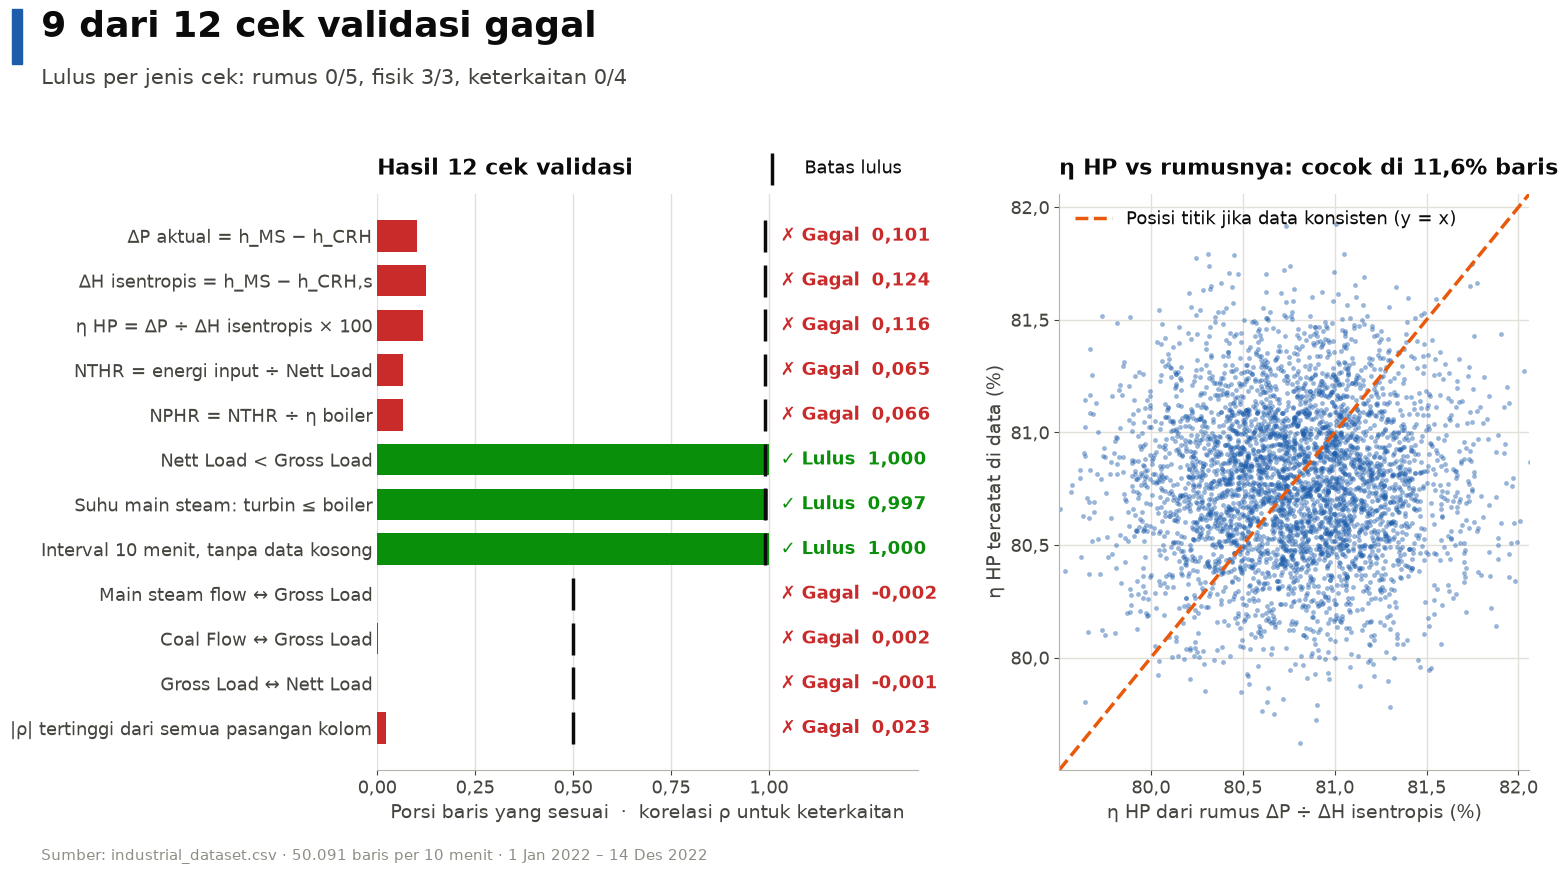

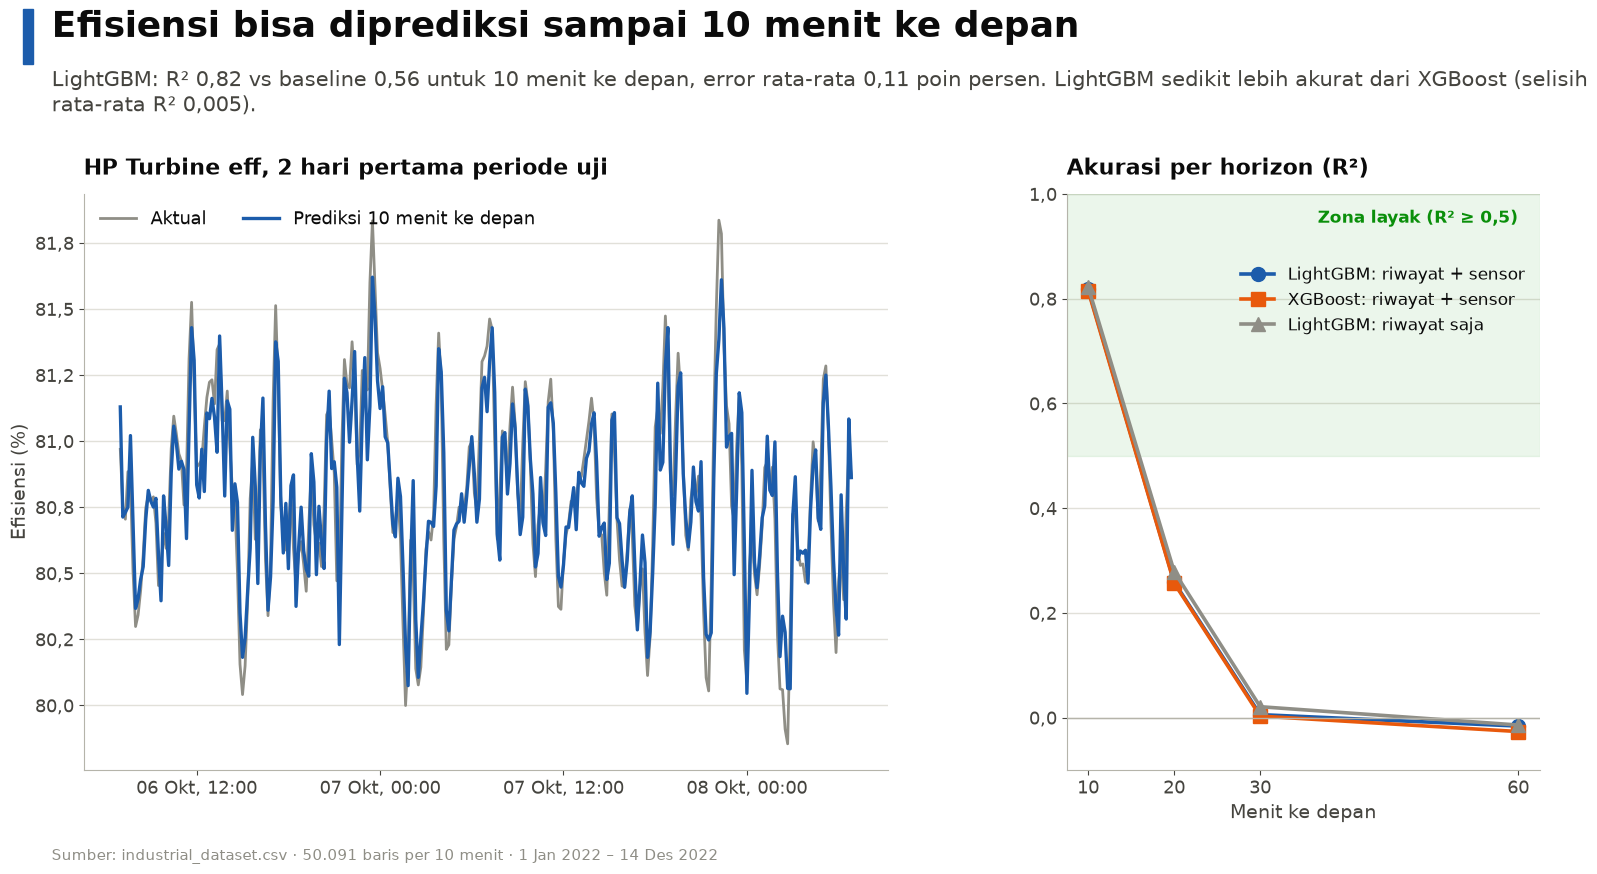

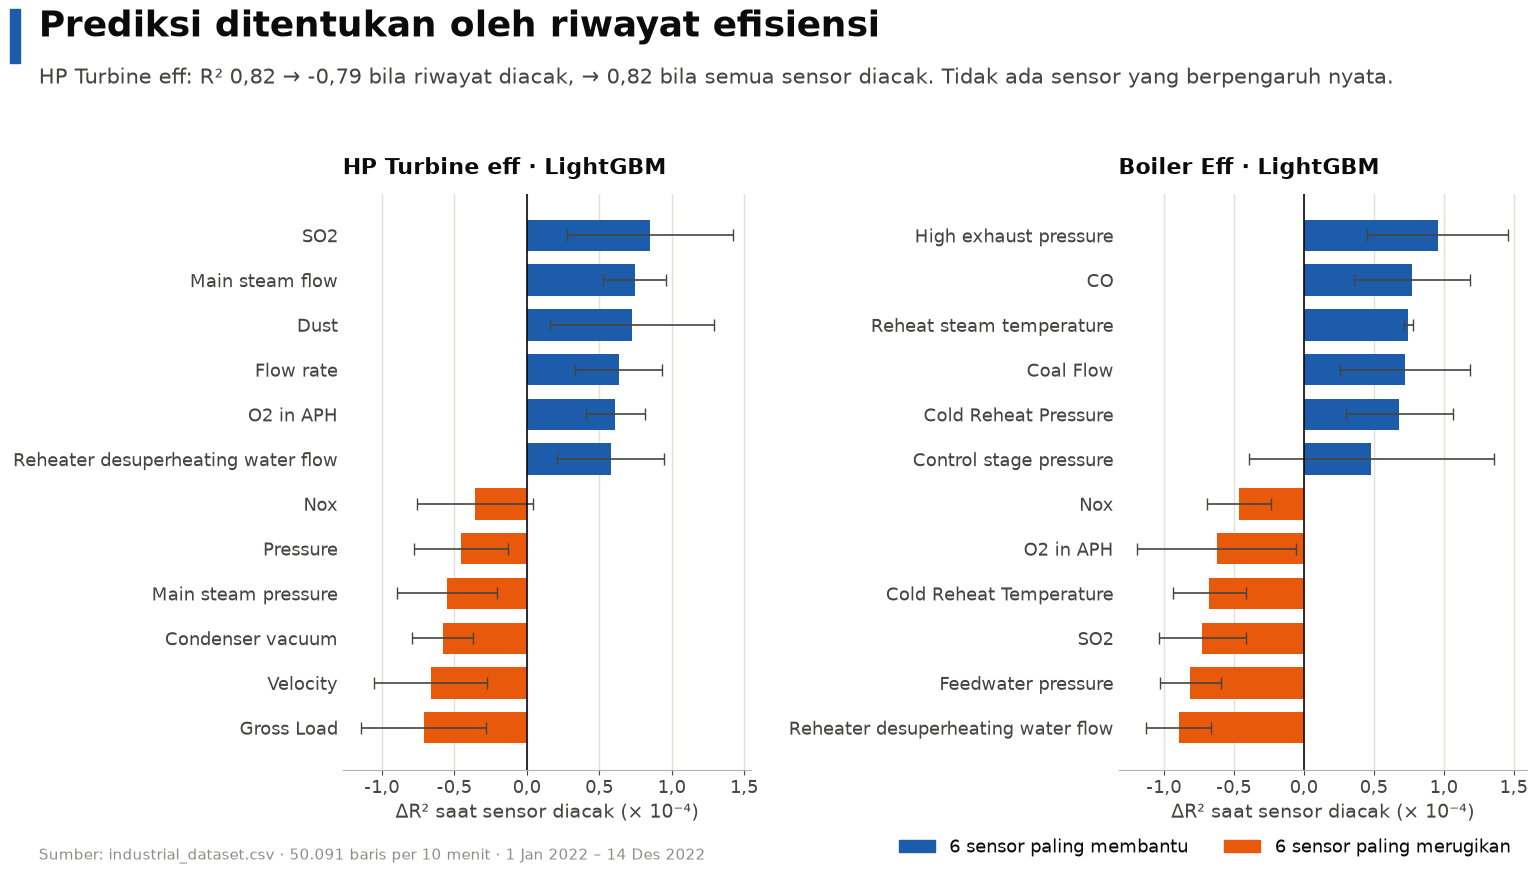

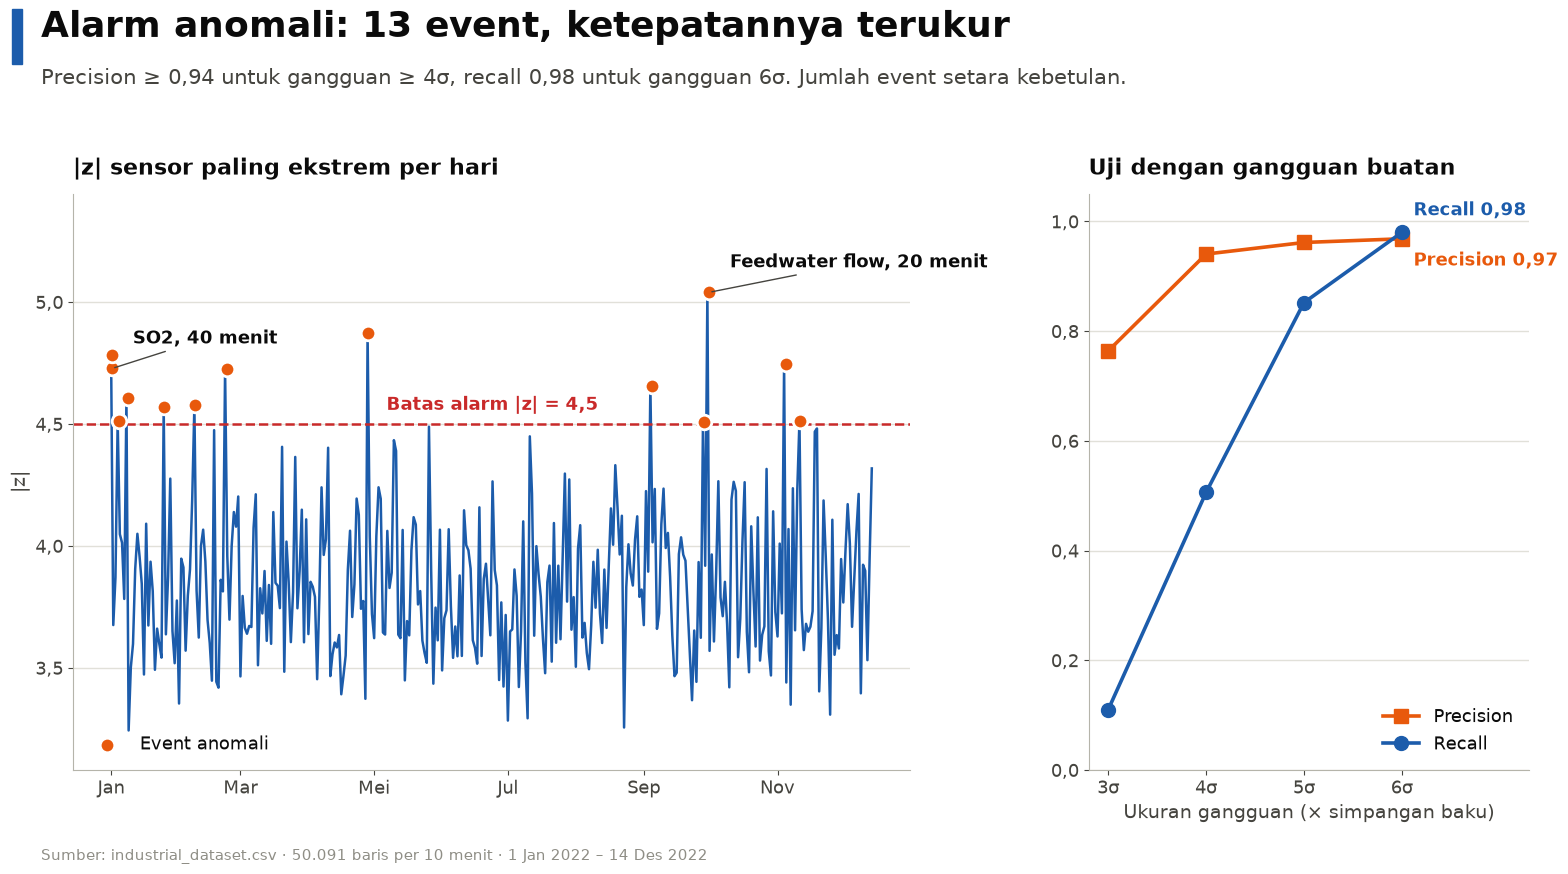

In [8]:
INK, INK2, GRID, AXIS, SURF = '#0b0b0b', '#45443f', '#e1e0d9', '#b5b4aa', '#ffffff'
BIRU, ORANYE, LULUS, GAGAL, ABU = '#1c5cab', '#e8590c', '#0a8f0a', '#c92a2a', '#8f8e86'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'font.size': 14, 'text.color': INK,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.edgecolor': AXIS,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 16, 'axes.labelsize': 14,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 14,
                     'legend.fontsize': 13, 'xtick.labelsize': 13, 'ytick.labelsize': 13})
angka = lambda d: FuncFormatter(lambda v, _: fmt(v, d))
BULAN = FuncFormatter(lambda v, _: BLN[mdates.num2date(v).month - 1])
grid = lambda ax, sumbu='y': (ax.grid(axis=sumbu, color=GRID, lw=1), ax.set_axisbelow(True))
DPI = 220

def slide(judul, sub, left=.06, **kw):
    fig, axes = plt.subplots(1, 2, figsize=(16, 9), **kw)
    fig.patches.append(plt.Rectangle((.022, .905), .006, .06, color=BIRU, transform=fig.transFigure))
    fig.text(.04, .965, judul, fontsize=26, fontweight='bold', va='top')
    fig.text(.04, .9, sub, fontsize=15, color=INK2, va='top', wrap=True)
    fig.text(.04, .02, f'Sumber: {CSV} · {fmt(len(df), 0)} baris per 10 menit · {PERIODE}', fontsize=11, color=ABU)
    fig.subplots_adjust(left=left, right=.97, top=.76, bottom=.12, wspace=.28)
    return fig, axes

# Slide 1: validasi
judul = 'Data lolos semua cek validasi' if n_gagal == 0 else f'{n_gagal} dari {len(validasi)} cek validasi gagal'
fig, (ax1, ax2) = slide(judul, f'Lulus per jenis cek: {rekap}', left=.25, gridspec_kw={'width_ratios': [1.15, 1]})
v = validasi[::-1].reset_index(drop=True)
ax1.barh(v.index, v.Nilai.clip(0, 1), height=.7, color=np.where(v.Status == 'Lulus', LULUS, GAGAL))
ax1.scatter(v.Batas, v.index, marker='|', s=500, linewidths=2.5, color=INK, zorder=3, label='Batas lulus')
for i, r in v.iterrows():
    ax1.text(1.03, i, f"{'✓' if r.Status == 'Lulus' else '✗'} {r.Status}  {fmt(r.Nilai, 3)}", va='center', fontsize=13,
             fontweight='bold', color=LULUS if r.Status == 'Lulus' else GAGAL)
ax1.set_yticks(v.index, v.Cek, fontsize=13)
ax1.tick_params(axis='y', length=0); ax1.spines['left'].set_visible(False)
ax1.set(xlim=(0, 1.38), xticks=[0, .25, .5, .75, 1], title=f'Hasil {len(validasi)} cek validasi',
        xlabel='Porsi baris yang sesuai  ·  korelasi ρ untuk keterkaitan')
ax1.xaxis.set_major_formatter(angka(2)); grid(ax1, 'x')
ax1.legend(loc='lower right', bbox_to_anchor=(1, 1), frameon=False)

eta, eta_rumus = rumus['η HP = ΔP ÷ ΔH isentropis × 100']
s = df.sample(min(4000, len(df)), random_state=0).index
lim = list(np.nanquantile(np.r_[eta, eta_rumus], [.001, .999]))
ax2.scatter(eta_rumus[s], eta[s], s=12, alpha=.45, color=BIRU, linewidths=0)
ax2.plot(lim, lim, color=ORANYE, ls='--', lw=2.5, label='Posisi titik jika data konsisten (y = x)')
ax2.set(xlim=lim, ylim=lim, title=f'η HP vs rumusnya: cocok di {fmt(eta_cocok * 100, 1)}% baris',
        xlabel='η HP dari rumus ΔP ÷ ΔH isentropis (%)', ylabel='η HP tercatat di data (%)')
ax2.xaxis.set_major_formatter(angka(1)); ax2.yaxis.set_major_formatter(angka(1)); grid(ax2, 'both')
ax2.legend(loc='upper left', frameon=False)
fig.savefig('images/01_validasi.png', dpi=DPI); plt.show()

# Slide 2: prediksi efisiensi
HP = TARGET[0]
d = model[HP]
jarak = max(PRED_LAYAK[0]) if PRED_LAYAK[0] else 0
judul = f'Efisiensi bisa diprediksi sampai {jarak} menit ke depan' if jarak else 'Efisiensi belum bisa diprediksi dengan andal'
fig, (ax1, ax2) = slide(judul, f"{d['nama'].split(':')[0]}: R² {fmt(R(HP, d['nama']), 2)} vs baseline {fmt(R(HP, PERSIST), 2)} untuk 10 menit ke depan, "
                        f"error rata-rata {fmt(R(HP, d['nama'], kol='MAE'), 2)} poin persen. {banding}.",
                        gridspec_kw={'width_ratios': [1.7, 1]})
w = slice(0, min(288, len(d['yte'])))  # 2 hari pertama periode uji
waktu = df['Timestamp'][d['yte'].index[w]]
ax1.plot(waktu, d['yte'].iloc[w], color=ABU, lw=2, label='Aktual')
ax1.plot(waktu, d['pred'][w], color=BIRU, lw=2.4, label='Prediksi 10 menit ke depan')
ax1.set(title=f'{HP.replace(" (%)", "")}, 2 hari pertama periode uji', ylabel='Efisiensi (%)')
ax1.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: (t := mdates.num2date(v)).strftime('%d ') + BLN[t.month - 1] + t.strftime(', %H:%M')))
ax1.yaxis.set_major_formatter(angka(1)); grid(ax1)
ax1.legend(loc='upper left', frameon=False, ncol=2)

for nama, warna, mk in [(LGB_S, BIRU, 'o'), (XGB_S, ORANYE, 's'), (RIWAYAT, ABU, '^')]:
    t = hasil[(hasil['Target'] == HP) & (hasil['Model'] == nama)]
    ax2.plot(t['Menit ke depan'], t['R²'], color=warna, lw=2.6, marker=mk, ms=10, label=nama)
ax2.axhspan(LAYAK, 1, color=LULUS, alpha=.08)
ax2.text(max(t['Menit ke depan']), .97, f'Zona layak (R² ≥ {fmt(LAYAK, 1)})', ha='right', va='top', fontsize=12, color=LULUS, fontweight='bold')
ax2.axhline(0, color=AXIS, lw=1)
ax2.set(ylim=(min(-.1, hasil['R²'][hasil['Model'] != PERSIST].min() - .05), 1), xticks=t['Menit ke depan'],
        title='Akurasi per horizon (R²)', xlabel='Menit ke depan')
ax2.yaxis.set_major_formatter(angka(1)); grid(ax2)
ax2.legend(loc='upper right', bbox_to_anchor=(1, .9), frameon=False, fontsize=12)
fig.savefig('images/02_prediksi.png', dpi=DPI); plt.show()

# Slide 3: pengaruh sensor
g = ringkas[HP]
judul = f'Prediksi ditentukan oleh {SUMBER[0]}' if len(set(SUMBER)) == 1 else 'Sumber prediksi berbeda per target'
fig, axes = slide(judul, f"{HP.replace(' (%)', '')}: R² {fmt(g['R² model'], 2)} → {fmt(g['R² jika riwayat diacak'], 2)} bila riwayat diacak, "
                  f"→ {fmt(g['R² jika semua sensor diacak'], 2)} bila semua sensor diacak. {SENSOR_NYATA}",
                  left=.23, gridspec_kw={'wspace': .9})
for ax, (y, p) in zip(axes, pengaruh.items()):
    s = p.sort_values('ΔR²')
    s = pd.concat([s.head(6), s.tail(6)])
    ax.barh(range(len(s)), s['ΔR²'] * 1e4, xerr=s['std'] * 1e4, height=.7, color=np.where(s['ΔR²'] > 0, BIRU, ORANYE),
            error_kw=dict(ecolor=INK2, lw=1.2, capsize=4))
    ax.axvline(0, color=INK, lw=1.2)
    ax.set_yticks(range(len(s)), [c.split(' (')[0] for c in s.index], fontsize=13)
    ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
    ax.set(title=f"{y.replace(' (%)', '')} · {ringkas[y]['Model'].split(':')[0]}", xlabel='ΔR² saat sensor diacak (× 10⁻⁴)')
    ax.xaxis.set_major_formatter(angka(1)); grid(ax, 'x')
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BIRU), plt.Rectangle((0, 0), 1, 1, color=ORANYE)],
           labels=['6 sensor paling membantu', '6 sensor paling merugikan'],
           loc='lower right', bbox_to_anchor=(.97, .005), ncol=2, frameon=False)
fig.savefig('images/03_pengaruh_sensor.png', dpi=DPI); plt.show()

# Slide 4: alarm anomali + kalibrasi
fig, (ax1, ax2) = slide(f'Alarm anomali: {len(event)} event, ketepatannya terukur',
                        f'Precision ≥ {fmt(kalibrasi.loc[K[1]:, "Precision"].min(), 2)} untuk gangguan ≥ {K[1]}σ, '
                        f'recall {fmt(kalibrasi["Recall"].iloc[-1], 2)} untuk gangguan {K[-1]}σ. '
                        + ('Jumlah event setara kebetulan.' if ACAK else 'Jumlah event jauh di atas kebetulan: perlu ditindaklanjuti.'),
                        gridspec_kw={'width_ratios': [1.9, 1]})
harian = pd.Series(np.abs(z_maks), index=df['Timestamp']).resample('D').max()
ax1.plot(harian.index, harian, color=BIRU, lw=1.8)
ax1.axhline(BATAS_Z, color=GAGAL, ls='--', lw=1.8)
ax1.text(harian.index[len(harian) // 2], BATAS_Z + .04, f'Batas alarm |z| = {fmt(BATAS_Z, 1)}', ha='center', va='bottom',
         fontsize=13, color=GAGAL, fontweight='bold')
ax1.scatter(event.Mulai, event.z_ekstrem.abs(), s=110, color=ORANYE, edgecolor=SURF, linewidth=2, zorder=3, label='Event anomali')
for _, e in event.nlargest(2, 'Durasi_menit').iterrows():
    ax1.annotate(f"{e.Sensor.split(' (')[0]}, {e.Durasi_menit} menit", xy=(e.Mulai, abs(e.z_ekstrem)),
                 xytext=(15, 18), textcoords='offset points', fontsize=13, color=INK, fontweight='bold',
                 arrowprops=dict(arrowstyle='-', color=INK2, lw=1))
ax1.set(ylim=(harian.min() * .95, max(harian.max(), BATAS_Z) * 1.08), title='|z| sensor paling ekstrem per hari', ylabel='|z|')
ax1.xaxis.set_major_formatter(BULAN); ax1.yaxis.set_major_formatter(angka(1)); grid(ax1)
ax1.legend(loc='lower left', frameon=False)

for kol, warna, mk, dy in [('Precision', ORANYE, 's', -.04), ('Recall', BIRU, 'o', .04)]:
    ax2.plot(K, kalibrasi[kol], color=warna, lw=2.6, marker=mk, ms=10, label=kol)
    ax2.text(K[-1] + .12, kalibrasi[kol].iloc[-1] + dy, f'{kol} {fmt(kalibrasi[kol].iloc[-1], 2)}', va='center',
             fontsize=13, fontweight='bold', color=warna)
ax2.set(xlim=(K[0] - .2, K[-1] + 1.3), ylim=(0, 1.05), xticks=K, title='Uji dengan gangguan buatan',
        xlabel='Ukuran gangguan (× simpangan baku)')
ax2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}σ'))
ax2.yaxis.set_major_formatter(angka(1)); grid(ax2)
ax2.legend(loc='lower right', frameon=False)
fig.savefig('images/04_anomali.png', dpi=DPI); plt.show()

## Kesimpulan

In [9]:
nama = lambda y: y.replace(' (%)', '')
jarak = lambda lay: f'layak dipakai sampai {max(lay)} menit ke depan' if lay else 'belum layak dipakai'
tulis('\n'.join([
    f'1. **Kualitas data:** {len(validasi) - n_gagal} dari {len(validasi)} cek lulus. {KESIMPULAN_DATA}',
    '2. **Prediksi efisiensi:** ' + '; '.join(f"{nama(y)} R² {fmt(R(y, model[y]['nama']), 2)} vs baseline {fmt(R(y, PERSIST), 2)}, {jarak(lay)}"
                                              for y, lay in zip(TARGET, PRED_LAYAK)) + f'. {banding}.',
    '3. **Faktor yang berpengaruh:** ' + '; '.join(f'{nama(y)} ditentukan oleh {s}' for y, s in zip(TARGET, SUMBER)) + '. ' + SENSOR_NYATA,
    f'4. **Alarm anomali:** {len(event)} event; precision ≥ {fmt(kalibrasi.loc[K[1]:, "Precision"].min(), 2)} untuk gangguan ≥ {K[1]}σ. '
    + ('Jumlah event setara kebetulan.' if ACAK else 'Jumlah event jauh di atas kebetulan, jadi perlu ditindaklanjuti.'),
    '',
    'Pipeline yang sama (validasi → forecasting → permutation importance → alarm terkalibrasi) bisa langsung dijalankan pada data DCS lain; '
    'semua angka dan kalimat di atas akan menyesuaikan.',
]))

1. **Kualitas data:** 3 dari 12 cek lulus. Tidak ada dua kolom yang bergerak bersama (|ρ| tertinggi 0,023), padahal di pembangkit nyata steam flow, beban, dan konsumsi batubara selalu saling terkait. Ciri ini khas data sintetis yang dibuat per kolom, jadi hasil model harus dibaca hati-hati.
2. **Prediksi efisiensi:** HP Turbine eff R² 0,82 vs baseline 0,56, layak dipakai sampai 10 menit ke depan; Boiler Eff R² 0,81 vs baseline 0,56, layak dipakai sampai 10 menit ke depan. LightGBM sedikit lebih akurat dari XGBoost (selisih rata-rata R² 0,005).
3. **Faktor yang berpengaruh:** HP Turbine eff ditentukan oleh riwayat efisiensi; Boiler Eff ditentukan oleh riwayat efisiensi. Tidak ada sensor yang berpengaruh nyata.
4. **Alarm anomali:** 13 event; precision ≥ 0,94 untuk gangguan ≥ 4σ. Jumlah event setara kebetulan.

Pipeline yang sama (validasi → forecasting → permutation importance → alarm terkalibrasi) bisa langsung dijalankan pada data DCS lain; semua angka dan kalimat di atas akan menyesuaikan.